15:37:33 - cmdstanpy - INFO - Chain [1] start processing
15:37:34 - cmdstanpy - INFO - Chain [1] done processing


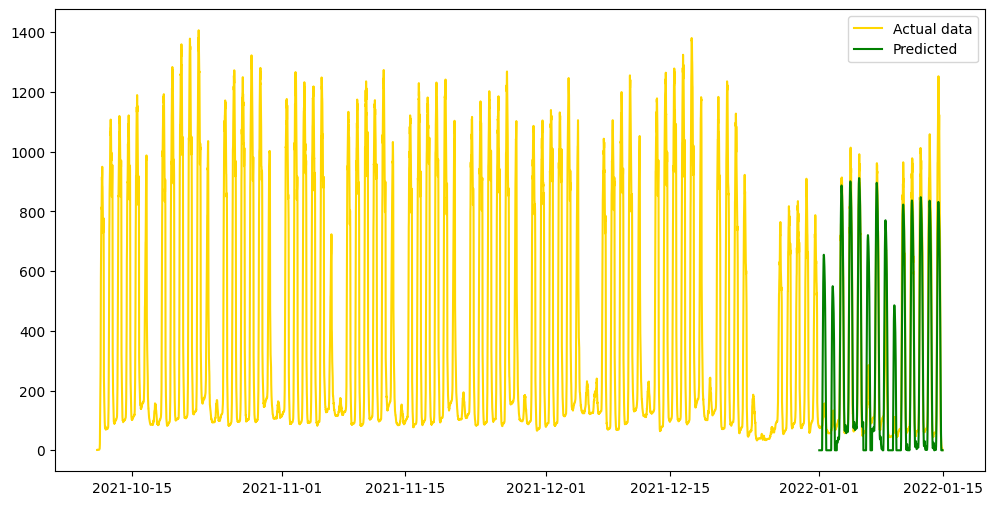

Prophet MAE: 101.77363229767029, RMSE: 150.04268297310276


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Add exogenous features
df['day_of_year'] = df.index.dayofyear
df['weekday'] = df.index.weekday
df['hour'] = df.index.hour

# Filter dates where is_holiday is 1
holidays_df = df[df['is_holiday'] == 1]

# Extract the dates
holiday_dates = holidays_df.index

holidays_df = pd.DataFrame({
    'holiday': 'finnishholidays',
    'ds': pd.to_datetime(holiday_dates),
})

# Split the data into training and test sets
end_date = pd.to_datetime('2022-01-01')
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Prepare the data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})
test_prophet = test_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})

# Initialize and fit the Prophet model
prophet_model = Prophet(
    holidays=holidays_df,
    daily_seasonality=True,
    changepoint_prior_scale=0.015,
    seasonality_prior_scale=1.0,
    holidays_prior_scale=1.0
)

# Add exogenous features to the model
exogenous_features = ["day_of_year", "weekday", "hour"]
for feature in exogenous_features:
    prophet_model.add_regressor(feature)

prophet_model.fit(train_prophet)

# Create a DataFrame to hold future dates for which we want predictions
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='15min')

# Add exogenous features to the future DataFrame
future['day_of_year'] = future['ds'].dt.dayofyear
future['weekday'] = future['ds'].dt.weekday
future['hour'] = future['ds'].dt.hour

# Make predictions
prophet_forecast = prophet_model.predict(future)

# Apply floor to prediction values to ensure they are not negative
prophet_forecast['yhat'] = prophet_forecast['yhat'].apply(lambda x: max(x, 0))

# Extract the forecast for the test period
prophet_pred = prophet_forecast.set_index('ds')['yhat'][-len(test_data):]

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Actual data', color='gold')
plt.plot(test_data.index, test_data['Parkings'], color='gold')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='green')
plt.legend()
plt.show()

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], prophet_pred))

print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')


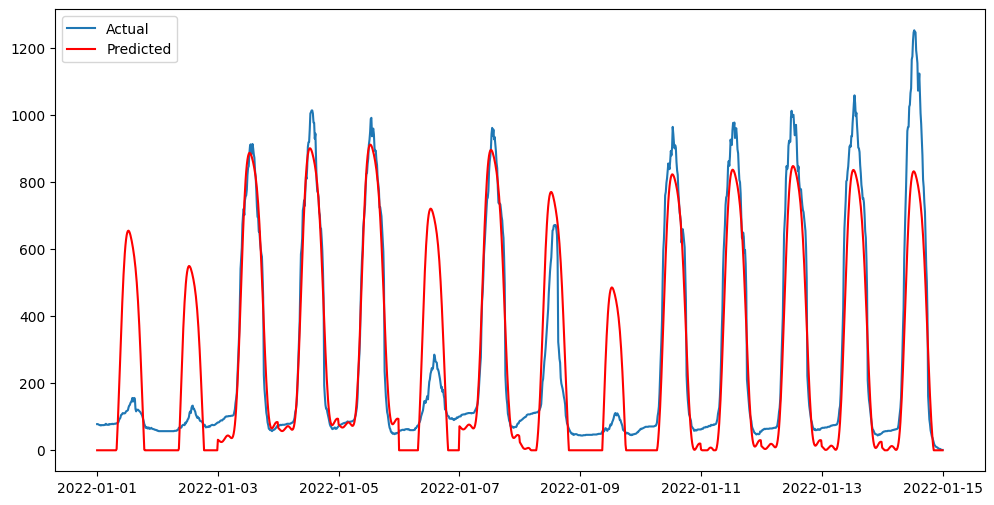

In [65]:
# Plot only the predicted part vs actual values in the test set
plt.figure(figsize=(12, 6))
plt.plot(test_data.index, test_data['Parkings'], label='Actual')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

In [54]:
from prophet.diagnostics import cross_validation, performance_metrics

# Perform cross-validation
df_cv = cross_validation(prophet_model, initial='30 days', period='14 days', horizon='7 days')

# Calculate performance metrics
df_p = performance_metrics(df_cv)
print(df_p.head())


  0%|          | 0/4 [00:00<?, ?it/s]15:06:53 - cmdstanpy - INFO - Chain [1] start processing
15:06:53 - cmdstanpy - INFO - Chain [1] done processing
 25%|██▌       | 1/4 [00:00<00:01,  2.34it/s]15:06:53 - cmdstanpy - INFO - Chain [1] start processing
15:06:54 - cmdstanpy - INFO - Chain [1] done processing
 50%|█████     | 2/4 [00:00<00:00,  2.08it/s]15:06:54 - cmdstanpy - INFO - Chain [1] start processing
15:06:54 - cmdstanpy - INFO - Chain [1] done processing
 75%|███████▌  | 3/4 [00:01<00:00,  1.69it/s]15:06:55 - cmdstanpy - INFO - Chain [1] start processing
15:06:55 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 4/4 [00:02<00:00,  1.71it/s]

          horizon           mse        rmse         mae      mape     mdape  \
0 0 days 16:45:00  53057.559706  230.342266  163.303848  2.048494  0.398603   
1 0 days 17:00:00  54209.824824  232.830034  166.851960  2.075628  0.404007   
2 0 days 17:15:00  55104.182795  234.742801  169.877817  2.098094  0.421234   
3 0 days 17:30:00  55790.257100  236.199613  172.426618  2.115345  0.434023   
4 0 days 17:45:00  56231.601823  237.132035  174.318547  2.127500  0.437670   

      smape  coverage  
0  0.693477  0.746269  
1  0.696652  0.735075  
2  0.699026  0.723881  
3  0.700615  0.716418  
4  0.700945  0.712687  
